# Phase 2 — 장미 잎 검출(Detection/Segmentation) 모델: YOLO26-seg 추가학습

**문제**: 원본 데이터는 *배경이 제거된(RGBA) 단일 잎 이미지 + 폴더(이미지) 단위 라벨* 뿐이라 박스 라벨이 없음.
**해결**: 알파 채널 = 정확한 잎 마스크 → 여러 잎을 배경 위에 합성(copy-paste)하면서 **폴리곤/박스 라벨을 자동 생성**.

1. 환경 확인
2. 원본 분할 (원본 stem 기준 → 증강본 누수 방지)
3. 합성 장면 생성 + YOLO-seg 라벨 자동 생성 (train / val / test)
4. 학습: `yolo26s-seg` (비교군 `yolo11s-seg`)
5. 검증: mAP(box/mask), 클래스별 AP, 혼동행렬 + 단일 잎 분류 정확도(macro-F1)
6. 실사 이미지 추론 / (선택) 2단계 파이프라인: 검출기 + Phase 1 분류기

> 클래스: `Black Spot Leaves / Fresh Leaves / Hole Leaves / Yellow Leaves`
> **실제 배경 사진**(화분·흙·벤치·온실 바닥 등, 잎 없이 촬영)을 `backgrounds/` 에 넣으면 실사 일반화가 크게 좋아집니다. 없으면 절차적 배경으로 대체.

In [3]:
!nvidia-smi
# %pip install -q -U ultralytics scikit-learn   # 2026-10-13 비활성화: 이 설치가 서버 opencv 4.7/4.11 충돌의 원인 (README 참고)

Mon Oct 12 05:28:46 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.126.20             Driver Version: 580.126.20     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla V100-SXM2-32GB           On  |   00000000:86:00.0 Off |                    0 |
| N/A   38C    P0             42W /  300W |       4MiB /  32768MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [4]:
import sys; sys.path.insert(0, '../common'); import paths  # 공용 경로 + opencv 충돌 우회 (cv2/ultralytics보다 먼저)
import cv2, ultralytics; print(cv2.__version__, ultralytics.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
4.7.0 8.4.175


In [5]:
import torch, ultralytics
print('torch', torch.__version__, '| cuda', torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0), 'VRAM %.1f GB' % (torch.cuda.get_device_properties(0).total_memory / 1e9))
print('ultralytics', ultralytics.__version__)

torch 2.3.0a0+40ec155e58.nv24.03 | cuda True
Tesla V100-SXM2-32GB VRAM 34.1 GB
ultralytics 8.4.175


## 1. 설정

In [8]:
import os, re, random, shutil, math
from collections import defaultdict, Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import numpy as np
import cv2
from PIL import Image, ImageFilter, ImageEnhance

SRC_DIR  = Path('../common/Dataset')  # 클래스별 RGBA png 폴더 (작업 디렉토리: model/v1)
BG_DIR   = Path('backgrounds')        # (권장) 실제 배경 사진 jpg/png. 없으면 절차적 배경
OUT_DIR  = Path('data/rose_seg')      # YOLO-seg 데이터셋 출력
SEED     = 42
SPLIT    = (0.70, 0.15, 0.15)         # 원본 stem 기준 train / val / test
N_SCENES = {'train': 6000, 'val': 800, 'test': 800}
IMG      = 640                        # 합성 장면 크기 (= 학습 imgsz)
LEAVES_PER_SCENE = (1, 6)             # 장면당 잎 개수 범위
LEAF_SCALE = (0.18, 0.55)             # 잎 긴 변 / 장면 크기
MAX_OVERLAP = 0.15                    # 새 잎이 기존 잎과 겹칠 수 있는 최대 비율
MIN_VISIBLE = 0.5                     # 가려진 뒤 남은 면적 비율이 이보다 작으면 장면에서 제외
SHADOW_P = 0.5                        # 그림자 합성 확률
WORKERS  = min(8, os.cpu_count() or 1)

random.seed(SEED); np.random.seed(SEED)
CLASSES = sorted(d.name for d in SRC_DIR.iterdir() if d.is_dir())
print(CLASSES)

def stem_of(name):
    # '20241104_101153_aug_108.png' -> '20241104_101153'
    return re.split(r'_aug_', Path(name).stem)[0]

['Black Spot Leaves', 'Fresh Leaves', 'Hole Leaves', 'Yellow Leaves']


## 2. 원본 분할 (누수 방지)

- 같은 원본에서 파생된 `_aug_` 파일은 **반드시 같은 split** 으로 → stem 단위 분할
- val/test 에는 **원본만** 사용 (오프라인 증강본은 평가를 낙관적으로 만듦)
- `Yellow Leaves` 는 고유 원본이 42장뿐 → test 에 약 6~7장. 지표 분산이 크므로 **데이터 추가 수집이 최우선 과제**

In [14]:
pools = {s: defaultdict(list) for s in ('train', 'val', 'test')}   # pools[split][cls_idx] = [Path]
for ci, c in enumerate(CLASSES):
    groups = defaultdict(list)
    for f in sorted((SRC_DIR / c).glob('*.png')):
        groups[stem_of(f.name)].append(f)
    stems = sorted(groups); random.shuffle(stems)
    n = len(stems); n_tr = int(n * SPLIT[0]); n_va = int(n * SPLIT[1])
    parts = {'train': stems[:n_tr], 'val': stems[n_tr:n_tr + n_va], 'test': stems[n_tr + n_va:]}
    for s, ss in parts.items():
        for st in ss:
            files = groups[st]
            if s != 'train':
                files = [f for f in files if '_aug_' not in f.name] or files[:1]
            pools[s][ci].extend(files)

for s in pools:
    print(f'{s:5s}', {CLASSES[ci]: len(v) for ci, v in pools[s].items()})

train {'Black Spot Leaves': 633, 'Fresh Leaves': 965, 'Hole Leaves': 629, 'Yellow Leaves': 121}
val   {'Black Spot Leaves': 78, 'Fresh Leaves': 206, 'Hole Leaves': 65, 'Yellow Leaves': 6}
test  {'Black Spot Leaves': 80, 'Fresh Leaves': 208, 'Hole Leaves': 67, 'Yellow Leaves': 7}


## 3. 합성 장면 + 자동 라벨 생성

장면 1장 생성 절차:
1. 배경 선택 (실사 배경 랜덤 crop → 없으면 단색/그라디언트/노이즈/흙 텍스처)
2. 클래스를 **균등 확률**로 뽑아 잎 1~6장 배치 → 클래스 불균형 자동 완화
3. 잎마다: 알파 bbox crop → 스케일 → 회전/뒤집기 → 밝기/대비/채도 지터(**색상(hue)은 건드리지 않음**: 노란잎 vs 정상잎 구분 단서)
4. 겹침 ≤ `MAX_OVERLAP` 위치 탐색, 소프트 그림자, 알파 블렌딩
5. **가시 마스크**(뒤에 놓인 잎에 가려진 부분 제거) → `cv2.findContours` → YOLO-seg 폴리곤 라벨

> 구멍(Hole) 잎은 구멍이 알파=0 이라 합성 시 배경이 비쳐 보임 → 실사와 동일한 외관이 자동으로 재현됨

In [15]:
BG_FILES = sorted(p for p in BG_DIR.rglob('*') if p.suffix.lower() in ('.jpg', '.jpeg', '.png')) if BG_DIR.exists() else []
print('real backgrounds:', len(BG_FILES))

def procedural_bg(w, h, rng):
    kind = rng.integers(0, 5)
    if kind == 0:   # 단색
        return np.full((h, w, 3), rng.integers(0, 256, 3), np.uint8)
    if kind == 1:   # 그라디언트
        a, b = rng.integers(0, 256, 3), rng.integers(0, 256, 3)
        t = np.linspace(0, 1, w)[None, :, None]
        return np.broadcast_to(a * (1 - t) + b * t, (h, w, 3)).astype(np.uint8)
    if kind == 2:   # 저주파 컬러 노이즈
        cell = int(rng.integers(8, 64))
        small = rng.integers(0, 256, (max(h // cell, 2), max(w // cell, 2), 3), dtype=np.uint8)
        return np.array(Image.fromarray(small).resize((w, h), Image.BICUBIC))
    if kind == 3:   # 흙/나무 느낌: 갈색 계열 + 고주파 노이즈
        base = np.array([rng.integers(60, 140), rng.integers(40, 100), rng.integers(20, 70)])
        noise = rng.normal(0, rng.uniform(5, 30), (h, w, 1))
        return np.clip(base + noise, 0, 255).astype(np.uint8)
    g = rng.integers(0, 60)  # 어두운 배경(원본 투명=검정과 유사)
    return np.full((h, w, 3), g, np.uint8)

def get_background(rng):
    if BG_FILES and rng.random() < 0.85:
        im = Image.open(BG_FILES[rng.integers(len(BG_FILES))]).convert('RGB')
        s = IMG / min(im.size) * rng.uniform(1.0, 1.6)
        im = im.resize((max(IMG, int(im.width * s)), max(IMG, int(im.height * s))), Image.BILINEAR)
        x, y = rng.integers(0, im.width - IMG + 1), rng.integers(0, im.height - IMG + 1)
        im = im.crop((x, y, x + IMG, y + IMG))
        if rng.random() < 0.5: im = im.transpose(Image.FLIP_LEFT_RIGHT)
        return np.asarray(im, np.float32)
    return procedural_bg(IMG, IMG, rng).astype(np.float32)

def prepare_leaf(path, rng):
    im = Image.open(path).convert('RGBA')
    im = im.crop(im.getchannel('A').point(lambda v: 255 if v > 16 else 0).getbbox())
    target = rng.uniform(*LEAF_SCALE) * IMG
    s = target / max(im.size)
    im = im.resize((max(8, round(im.width * s)), max(8, round(im.height * s))), Image.LANCZOS)
    if rng.random() < 0.5: im = im.transpose(Image.FLIP_LEFT_RIGHT)
    im = im.rotate(rng.uniform(0, 360), resample=Image.BICUBIC, expand=True)
    bb = im.getchannel('A').point(lambda v: 255 if v > 16 else 0).getbbox()
    im = im.crop(bb)
    if max(im.size) > IMG * 0.9:
        im.thumbnail((int(IMG * 0.9), int(IMG * 0.9)), Image.LANCZOS)
    rgb, a = im.convert('RGB'), im.getchannel('A')
    rgb = ImageEnhance.Brightness(rgb).enhance(rng.uniform(0.75, 1.25))
    rgb = ImageEnhance.Contrast(rgb).enhance(rng.uniform(0.8, 1.2))
    rgb = ImageEnhance.Color(rgb).enhance(rng.uniform(0.85, 1.15))
    rgb.putalpha(a)
    return rgb

def mask_to_polygon(mask):
    """이진 마스크 -> 정규화된 YOLO-seg 폴리곤 1개 (여러 조각이면 가장 큰 조각)"""
    cnts, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not cnts:
        return None
    c = max(cnts, key=cv2.contourArea)
    c = cv2.approxPolyDP(c, 0.002 * cv2.arcLength(c, True), True).reshape(-1, 2)
    if len(c) < 3:
        return None
    return (c.astype(np.float32) / IMG).clip(0, 1).flatten()

def make_scene(pool, rng):
    canvas = get_background(rng)
    occ = np.zeros((IMG, IMG), bool)
    insts = []   # (cls, full_mask)
    for _ in range(rng.integers(LEAVES_PER_SCENE[0], LEAVES_PER_SCENE[1] + 1)):
        ci = int(rng.integers(len(CLASSES)))               # 클래스 균등 샘플링
        leaf = prepare_leaf(pool[ci][rng.integers(len(pool[ci]))], rng)
        w, h = leaf.size
        la = np.asarray(leaf.getchannel('A'), np.float32) / 255.0
        lm = la > 0.5
        for _try in range(15):
            x, y = int(rng.integers(0, IMG - w + 1)), int(rng.integers(0, IMG - h + 1))
            if (occ[y:y + h, x:x + w] & lm).sum() <= MAX_OVERLAP * lm.sum():
                break
        else:
            continue
        if rng.random() < SHADOW_P:  # 소프트 그림자
            sh = np.asarray(leaf.getchannel('A').filter(ImageFilter.GaussianBlur(rng.uniform(3, 10))), np.float32) / 255.0
            dx, dy = rng.integers(-12, 13, 2)
            x0, y0, x1, y1 = max(0, x + dx), max(0, y + dy), min(IMG, x + dx + w), min(IMG, y + dy + h)
            if x1 > x0 and y1 > y0:
                s = sh[y0 - y - dy:y1 - y - dy, x0 - x - dx:x1 - x - dx][..., None]
                canvas[y0:y1, x0:x1] *= 1 - s * rng.uniform(0.2, 0.5)
        rgb = np.asarray(leaf.convert('RGB'), np.float32)
        a = la[..., None]
        canvas[y:y + h, x:x + w] = rgb * a + canvas[y:y + h, x:x + w] * (1 - a)
        m = np.zeros((IMG, IMG), bool); m[y:y + h, x:x + w] = lm
        occ |= m
        insts.append((ci, m))

    labels = []
    for i, (ci, m) in enumerate(insts):
        vis = m.copy()
        for _, m2 in insts[i + 1:]:
            vis &= ~m2
        if vis.sum() < MIN_VISIBLE * m.sum():
            continue
        poly = mask_to_polygon(vis)
        if poly is not None:
            labels.append(f'{ci} ' + ' '.join(f'{v:.5f}' for v in poly))
    # 글로벌 지터(노이즈/블러)로 합성 경계 흔적 완화
    if rng.random() < 0.3:
        canvas += rng.normal(0, rng.uniform(2, 6), canvas.shape)
    img = Image.fromarray(canvas.clip(0, 255).astype(np.uint8))
    if rng.random() < 0.2:
        img = img.filter(ImageFilter.GaussianBlur(rng.uniform(0.3, 1.0)))
    return img, labels

real backgrounds: 0


In [16]:
def build_split(split, n):
    (OUT_DIR / 'images' / split).mkdir(parents=True, exist_ok=True)
    (OUT_DIR / 'labels' / split).mkdir(parents=True, exist_ok=True)
    sid = ('train', 'val', 'test').index(split)
    def job(i):
        rng = np.random.default_rng([SEED, sid, i])       # 장면별 고정 시드 → 재현 가능
        img, labels = make_scene(pools[split], rng)
        img.save(OUT_DIR / 'images' / split / f'{split}_{i:05d}.jpg', quality=92)
        (OUT_DIR / 'labels' / split / f'{split}_{i:05d}.txt').write_text('\n'.join(labels))
        return [int(l.split()[0]) for l in labels]
    with ThreadPoolExecutor(WORKERS) as ex:
        cnt = Counter(c for cs in ex.map(job, range(n)) for c in cs)
    print(f'{split:5s} scenes={n}', {CLASSES[k]: cnt[k] for k in range(len(CLASSES))})

if OUT_DIR.exists():
    shutil.rmtree(OUT_DIR)
for s, n in N_SCENES.items():
    build_split(s, n)

DATA_YAML = OUT_DIR / 'rose_seg.yaml'
DATA_YAML.write_text(
    f'path: {OUT_DIR.resolve().as_posix()}\ntrain: images/train\nval: images/val\ntest: images/test\n'
    'names:\n' + ''.join(f'  {i}: {c}\n' for i, c in enumerate(CLASSES)))
print(DATA_YAML.read_text())

train scenes=6000 {'Black Spot Leaves': 4924, 'Fresh Leaves': 4961, 'Hole Leaves': 5009, 'Yellow Leaves': 5005}
val   scenes=800 {'Black Spot Leaves': 625, 'Fresh Leaves': 614, 'Hole Leaves': 680, 'Yellow Leaves': 638}
test  scenes=800 {'Black Spot Leaves': 648, 'Fresh Leaves': 633, 'Hole Leaves': 636, 'Yellow Leaves': 675}
path: /helpai-storage/model/data/rose_seg
train: images/train
val: images/val
test: images/test
names:
  0: Black Spot Leaves
  1: Fresh Leaves
  2: Hole Leaves
  3: Yellow Leaves



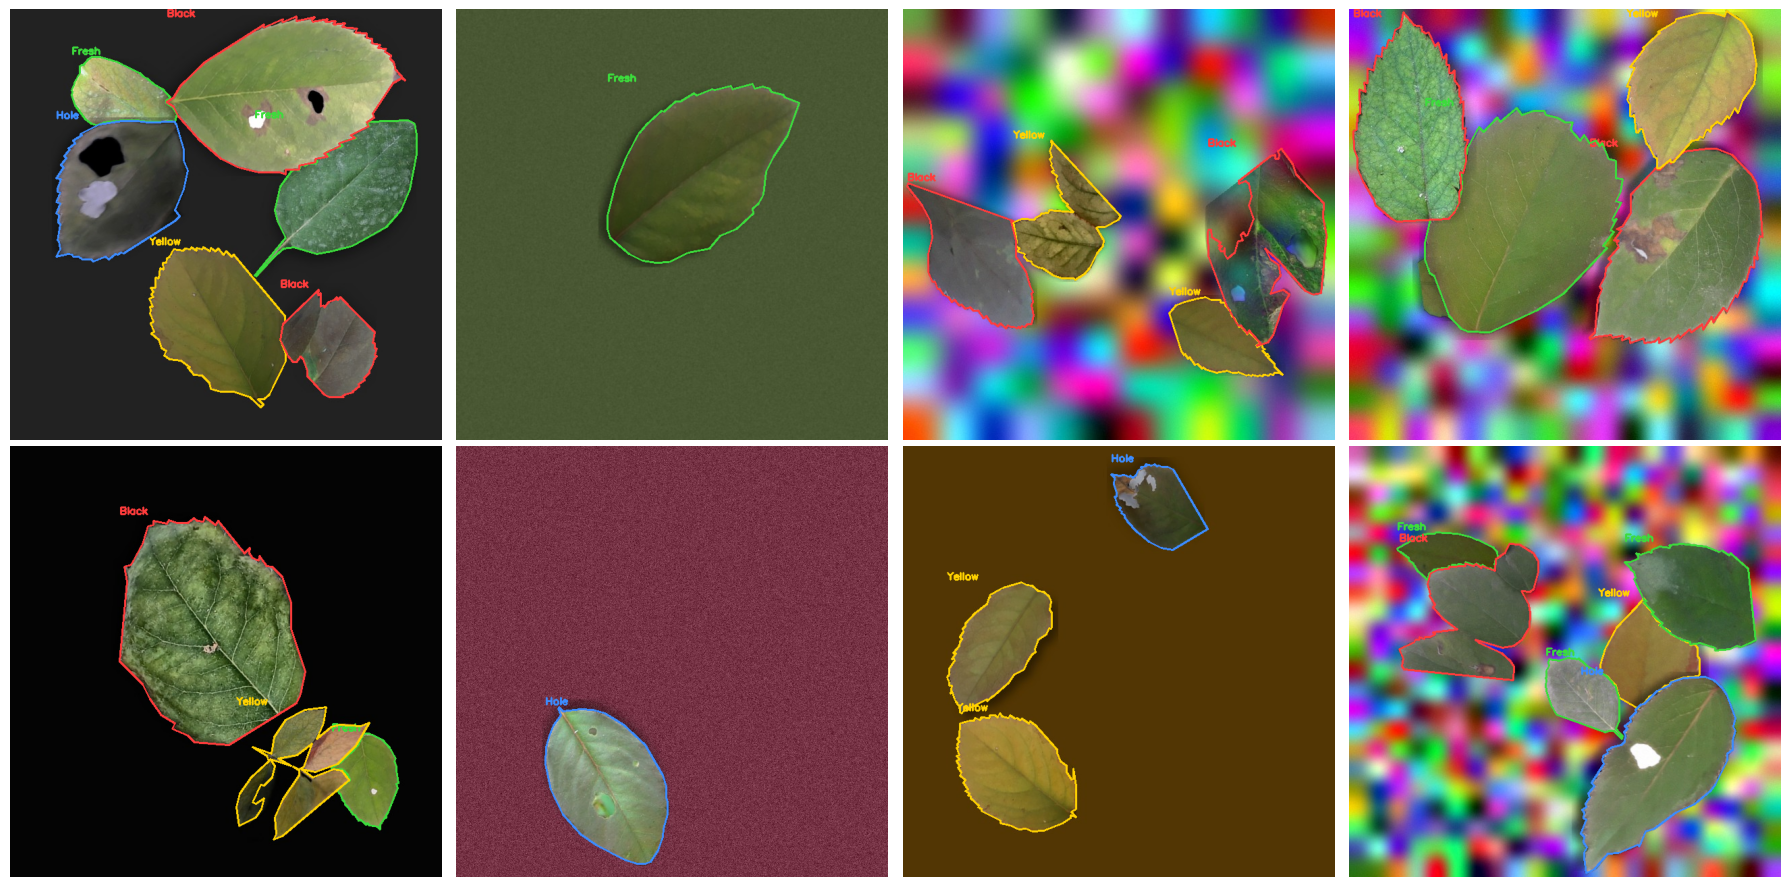

In [10]:
# 라벨 시각화 검증 — 폴리곤이 잎 윤곽과 정확히 맞는지 반드시 눈으로 확인
import matplotlib.pyplot as plt
COLORS = [(255, 60, 60), (60, 220, 60), (60, 140, 255), (255, 210, 0)]

def draw_labels(img_path, lbl_path):
    im = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    for line in Path(lbl_path).read_text().splitlines():
        v = line.split(); ci = int(v[0])
        pts = (np.array(v[1:], np.float32).reshape(-1, 2) * IMG).astype(np.int32)
        cv2.polylines(im, [pts], True, COLORS[ci], 2)
        x, y, w, h = cv2.boundingRect(pts)
        cv2.putText(im, CLASSES[ci].split()[0], (x, max(12, y - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, COLORS[ci], 2)
    return im

samples = random.sample(sorted((OUT_DIR / 'images' / 'train').glob('*.jpg')), 8)
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, p in zip(axes.flat, samples):
    ax.imshow(draw_labels(p, OUT_DIR / 'labels' / 'train' / (p.stem + '.txt'))); ax.axis('off')
plt.tight_layout(); plt.show()

## 4. 학습

**아키텍처 선택 근거**
| 항목 | 선택 | 이유 |
|---|---|---|
| 태스크 | **segment** (`-seg`) | 알파 마스크로 픽셀 라벨이 공짜 → 박스보다 정보량↑, 겹친 잎 분리에 유리. 박스만 필요하면 결과의 `.boxes` 사용 |
| 베이스 | **YOLO26s-seg** (비교: YOLO11s-seg) | NMS-free 엔드투엔드, 소형 객체/엣지 추론에 유리. 데이터 수천 장 규모에는 s 가 적정 (m 은 과적합 위험↑, 실사 데이터 늘면 시도) |
| 사전학습 | COCO 가중치 전이 | 소량 데이터 → 백본 특징 재사용 필수 |
| imgsz | 640 | 병변(흑점·구멍)이 작아 해상도 유지가 중요 |
| 증강 | hue 최소화 | 노란잎 vs 정상잎은 **색이 곧 라벨** → `hsv_h` 를 거의 0 으로 |

- V100(16/32GB): `batch=32` 기준. OOM 시 16 으로. 로컬 4GB GPU 에서는 `batch=4, imgsz=512` + `yolo26n-seg` 권장
- `freeze=10` 으로 백본을 얼려 먼저 빠르게 확인 → 이후 전체 미세조정도 가능 (아래는 전체 미세조정)

In [11]:
DATA_YAML = OUT_DIR / 'rose_seg.yaml'
print(DATA_YAML.read_text())
for s in ('train', 'val', 'test'):
    print(s, len(list((OUT_DIR / 'images' / s).glob('*.jpg'))))

path: /helpai-storage/model/data/rose_seg
train: images/train
val: images/val
test: images/test
names:
  0: Black Spot Leaves
  1: Fresh Leaves
  2: Hole Leaves
  3: Yellow Leaves

train 6000
val 800
test 800


In [ ]:
from ultralytics import YOLO

EXPERIMENTS = ['../common/weights/yolo26s-seg.pt', '../common/weights/yolo11s-seg.pt']
PROJECT = Path('runs').resolve()   # model/v1/runs
COMMON = dict(
    data=str(DATA_YAML), imgsz=IMG, epochs=100, batch=32, device=0, workers=4,
    patience=20, seed=SEED, project=str(PROJECT), exist_ok=True, cos_lr=True,
    # 증강: 색상(hue) 최소화, 기하 변환 위주
    hsv_h=0.005, hsv_s=0.3, hsv_v=0.35, degrees=15, scale=0.4, translate=0.1,
    fliplr=0.5, flipud=0.5, mosaic=1.0, close_mosaic=10, mixup=0.0, copy_paste=0.0,
    plots=True,
)

weights = {}
for w in EXPERIMENTS:
    name = Path(w).stem
    YOLO(w).train(name=name, **COMMON)
    weights[name] = PROJECT / name / 'weights' / 'best.pt'
weights

Ultralytics 8.4.175 🚀 Python-3.10.12 torch-2.3.0a0+40ec155e58.nv24.03 CUDA:0 (Tesla V100-SXM2-32GB, 32494MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=data/rose_seg/rose_seg.yaml, degrees=15, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.005, hsv_s=0.3, hsv_v=0.35, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26s-seg, nbs=64, nms=None, o

## 5. 검증

### 5-1. 합성 test 장면 — 검출/분할 지표
- `mAP50`, `mAP50-95` (box / mask), 클래스별 AP, Ultralytics 혼동행렬 (`background` 행/열 = 미검출/오검출)

In [ ]:
import pandas as pd

rows = []
for name, wp in weights.items():
    m = YOLO(wp).val(data=str(DATA_YAML), split='test', imgsz=IMG, batch=32, device=0,
                     project=str(PROJECT), name=f'{name}_test', exist_ok=True, plots=True, verbose=False)
    rows.append(dict(model=name, box_mAP50=m.box.map50, box_mAP=m.box.map, mask_mAP50=m.seg.map50, mask_mAP=m.seg.map,
                     **{f'AP50:{CLASSES[int(ci)].split()[0]}': ap for ci, ap in zip(m.box.ap_class_index, m.box.ap50)}))
    print(name, '→', PROJECT / f'{name}_test', '(confusion_matrix.png, PR curves)')
pd.DataFrame(rows).set_index('model').round(3)

### 5-2. 단일 잎 분류 정확도 (Phase 1 과 동일 기준 비교)
- test 원본 잎을 각각 배경 1장에 합성 → 가장 신뢰도 높은 검출의 클래스로 판정
- 미검출은 `missed` 로 집계. **Yellow 의 recall** 을 특히 확인

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

def single_leaf_scene(path, rng):
    canvas = get_background(rng)
    leaf = prepare_leaf(path, rng)
    w, h = leaf.size
    x, y = (IMG - w) // 2, (IMG - h) // 2
    a = np.asarray(leaf.getchannel('A'), np.float32)[..., None] / 255.0
    canvas[y:y + h, x:x + w] = np.asarray(leaf.convert('RGB'), np.float32) * a + canvas[y:y + h, x:x + w] * (1 - a)
    return Image.fromarray(canvas.clip(0, 255).astype(np.uint8))

rng = np.random.default_rng(SEED + 999)
test_items = [(single_leaf_scene(f, rng), ci) for ci in range(len(CLASSES)) for f in pools['test'][ci]]
labels_ext = CLASSES + ['missed']

for name, wp in weights.items():
    model = YOLO(wp)
    y_true, y_pred = [], []
    for i in range(0, len(test_items), 32):
        batch = test_items[i:i + 32]
        for r, (_, ci) in zip(model.predict([im for im, _ in batch], imgsz=IMG, conf=0.25, device=0, verbose=False), batch):
            y_true.append(ci)
            y_pred.append(int(r.boxes.cls[r.boxes.conf.argmax()]) if len(r.boxes) else len(CLASSES))
    print(f'===== {name} =====')
    print(classification_report(y_true, y_pred, labels=list(range(len(CLASSES))), target_names=CLASSES, digits=3, zero_division=0))
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, labels=list(range(len(labels_ext)))),
                           display_labels=labels_ext).plot(xticks_rotation=30, cmap='Greens')
    plt.title(name); plt.show()

## 6. 실사 이미지 추론

합성 데이터 지표는 **상한값**입니다. 실제 촬영 사진(여러 잎, 실제 배경)으로 반드시 확인하세요.
`../common/real_images/` 에 사진을 넣고 실행 → 오검출 사례를 모아 라벨링(CVAT/Label Studio, YOLO-seg 포맷) 후 train 에 추가하면 도메인 갭이 빠르게 줄어듭니다.

In [ ]:
BEST = weights['yolo26s-seg']   # 5절 결과로 선택
REAL_DIR = Path('../common/real_images')
if REAL_DIR.exists():
    res = YOLO(BEST).predict(source=str(REAL_DIR), imgsz=IMG, conf=0.3, device=0,
                             save=True, project=str(PROJECT), name='real_pred', exist_ok=True)
    for r in res[:6]:
        plt.figure(figsize=(8, 8)); plt.imshow(r.plot()[..., ::-1]); plt.axis('off'); plt.show()
else:
    print('../common/real_images/ 폴더가 없습니다 — 실사 사진을 넣고 다시 실행하세요.')

### (선택) 2단계 파이프라인: 검출기 → Phase 1 분류기
- 검출기는 "잎 위치"만 잘 찾으면 되고, 상태 판정은 고해상도 crop 을 보는 분류기가 담당 → 작은 흑점/구멍에 강함
- 두 모델의 판정이 다르면 신뢰도가 높은 쪽을 채택하거나, 분류기 결과를 우선 사용

In [ ]:
CLS_WEIGHTS = Path('../phase1_cls/runs/rose_cls/yolo26s-cls/weights/best.pt')   # Phase 1 결과

def two_stage(img_path, det, cls, det_conf=0.3, pad=0.08):
    im = Image.open(img_path).convert('RGB')
    r = det.predict(im, imgsz=IMG, conf=det_conf, device=0, verbose=False)[0]
    out = []
    for (x1, y1, x2, y2), dc, dconf in zip(r.boxes.xyxy.tolist(), r.boxes.cls.tolist(), r.boxes.conf.tolist()):
        px, py = (x2 - x1) * pad, (y2 - y1) * pad
        crop = im.crop((max(0, x1 - px), max(0, y1 - py), min(im.width, x2 + px), min(im.height, y2 + py)))
        p = cls.predict(crop, imgsz=320, device=0, verbose=False)[0].probs
        out.append(dict(box=[round(v) for v in (x1, y1, x2, y2)], det=CLASSES[int(dc)], det_conf=round(dconf, 3),
                        cls=cls.names[int(p.top1)], cls_conf=round(float(p.top1conf), 3)))
    return out

if CLS_WEIGHTS.exists() and REAL_DIR.exists():
    det_model, cls_model = YOLO(BEST), YOLO(CLS_WEIGHTS)
    for p in sorted(REAL_DIR.glob('*'))[:3]:
        print(p.name, two_stage(p, det_model, cls_model))

### 7. 배포용 내보내기

In [ ]:
# ONNX (CPU/엣지) / TensorRT (Jetson·서버 GPU). YOLO26 은 NMS-free 라 후처리가 단순
YOLO(BEST).export(format='onnx', imgsz=IMG, dynamic=False, simplify=True)
# YOLO(BEST).export(format='engine', imgsz=IMG, half=True, device=0)